# Regressão Linear do zero

A regressão linear estima o valor esperado de uma **variável dependente (Y)** condicionado a uma ou mais **variáveis independentes (X)**, e é caracterizada por $\hat{y} = w \cdot x + b$. Para uma única variável preditora, a equação tem um **coeficiente angular (w)** e um **intercepto (b)**, e representa a reta que se propõe a explicar a relação linear entre as variáveis.

Neste notebook, a regressão linear é implementada de duas maneiras igualmente válidas: a **solução analítica**, uma fórmula fechada, computacionalmente rápida e útil para conjuntos de dados pequenos e médios; e a **otimização por gradientes**, mais apropriada para grandes volumes de dados e generalizável a outros modelos. Ambas são escritas em *Python* com a biblioteca *NumPy* (em `src/linear_regression.py`) e, depois, comparadas com `sklearn.linear_model.LinearRegression`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from src.linear_regression import RegressaoLinear, RegressaoLinearGD

SEED = 42
np.random.seed(SEED)


def mse(modelo, x, y):
    #Erro quadrático médio de qualquer modelo que tenha o método predict.
    return np.mean((y - modelo.predict(x)) ** 2)

## Derivação do Gradiente

Para desenvolver ambos os métodos, precisamos de equações que justifiquem a melhora do modelo. Na Regressão Linear, podemos avaliar os pesos com base em duas métricas essenciais: a função de perda MSE (*Mean Squared Error*, ou MSD, *Mean Squared Deviation*) e o Coeficiente de Determinação (R²). Aqui, ambos os métodos são desenvolvidos a partir da função de perda MSE.

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_{i}-\hat{y}_{i})^2$$
$$\text{onde}$$
$$\hat{y}_{i} = w \cdot x_{i} + b$$

Nessa fórmula, temos a média dos quadrados das diferenças (resíduos) entre os dados e o valor predito pela reta. Se usássemos apenas a média dos resíduos, erros positivos e negativos se cancelariam e uma reta ruim poderia parecer perfeita. Elevar ao quadrado evita esse cancelamento e, de quebra, penaliza mais os erros grandes.

A **solução analítica**, que fornece fórmulas únicas para o **coeficiente angular (w)** e o **intercepto (b)**, permite computar os valores de uma única vez. Para obtê-la, precisamos encontrar o ponto mínimo da função de perda usando derivadas parciais e, para isso, igualamos as derivadas a zero:

$$L(w, b) = \frac{1}{n}\sum_{i=1}^{n}(y_{i}-(w \cdot x_{i} + b))^2$$

$$\frac{\partial L}{\partial w} = 0 \quad \text{e} \quad \frac{\partial L}{\partial b} = 0$$

Podemos começar por **b**:

$$\frac{\partial L}{\partial b} = \frac{\partial}{\partial b}\left[\frac{1}{n}\sum_{i=1}^{n}(y_{i}-(w \cdot x_{i} + b))^2\right] = 0$$

Utilizamos a Regra da Cadeia:

$$\frac{1}{n}\sum_{i=1}^{n}2(y_{i}-(w \cdot x_{i} + b)) \cdot \frac{\partial}{\partial b} (y_{i}-(w \cdot x_{i} + b)) = 0$$
$$\frac{1}{n}\sum_{i=1}^{n}2(y_{i}-(w \cdot x_{i} + b)) \cdot (-1) = 0$$
$$\frac{-2}{n}\sum_{i=1}^{n}(y_{i} - w \cdot x_{i} - b) = 0$$

Como $\frac{-2}{n} \neq 0$, podemos multiplicar ambos os lados por $\frac{-n}{2}$ sem alterar a igualdade:

$$\sum_{i=1}^{n}y_{i} - w\sum_{i=1}^{n}x_{i} - bn = 0$$
$$\frac{\sum y_{i} - w\sum x_{i} - bn}{n} = 0$$
$$\bar{y} - w \cdot \bar{x} - b = 0$$
$$\boxed{b = \bar{y} - w \cdot \bar{x}}$$


Agora que encontramos o intercepto ótimo para qualquer valor de $w$, partimos para o coeficiente angular. O primeiro passo é idêntico ao anterior, com a diferença de que derivamos em relação a **w**:

$$\frac{1}{n}\sum_{i=1}^{n}2(y_{i}-(w \cdot x_{i} + b)) \cdot \frac{\partial}{\partial w} (y_{i}-(w \cdot x_{i} + b)) = 0$$
$$\frac{1}{n}\sum_{i=1}^{n}2(y_{i}-(w \cdot x_{i} + b)) \cdot (-x_{i}) = 0$$
$$\frac{-2}{n}\sum_{i=1}^{n}(y_{i} - w \cdot x_{i} - b) \cdot x_{i}= 0$$

Novamente, multiplicando ambos os lados por $\frac{-n}{2}$, eliminamos a fração inicial:

$$\sum_{i=1}^{n}(y_{i}x_{i} - wx_{i}^2 - bx_{i})= 0$$
$$\sum_{i=1}^{n}y_{i}x_{i} - w\sum_{i=1}^{n}x_{i}^2 - b\sum_{i=1}^{n}x_{i} = 0$$

Sabemos que $b = \bar{y} - w \cdot \bar{x}$, portanto:

$$w\sum_{i=1}^{n}x_{i}^2 = \sum_{i=1}^{n}y_{i}x_{i} - (\bar{y} - w \cdot \bar{x})\sum_{i=1}^{n}x_{i}$$
$$w\sum_{i=1}^{n}x_{i}^2 = \sum_{i=1}^{n}y_{i}x_{i} - \bar{y}\sum_{i=1}^{n}x_{i} + w \cdot \bar{x}\sum_{i=1}^{n}x_{i}$$
$$w\sum_{i=1}^{n}x_{i}^2 - w \cdot \bar{x}\sum_{i=1}^{n}x_{i} = \sum_{i=1}^{n}y_{i}x_{i} - \bar{y}\sum_{i=1}^{n}x_{i}$$

Fatoramos e expandimos:

$$w\sum_{i=1}^{n}x_{i}(x_{i} - \bar{x}) = \sum_{i=1}^{n}y_{i}x_{i} - \bar{y}\sum_{i=1}^{n}x_{i}$$
$$w = \frac{\sum y_{i}x_{i} - \bar{y}\sum x_{i}}{\sum x_{i}(x_{i} - \bar{x})}$$
$$w = \frac{\sum y_{i}x_{i} - \frac{\sum y_{i} \cdot \sum x_{i}}{n}}{\sum x_{i}^2 - \frac{(\sum x_{i})^2}{n}}$$

Eliminamos essas frações desagradáveis multiplicando denominador e numerador por **n** e, dessa forma, chegamos ao resultado final:

$$\boxed{w = \frac{n\sum_{i=1}^{n} y_{i}x_{i} - \sum_{i=1}^{n} y_{i} \sum_{i=1}^{n} x_{i}}{n\sum_{i=1}^{n} x_{i}^2 - \left(\sum_{i=1}^{n} x_{i}\right)^2}}$$

Dessa forma, obtemos as duas funções do ponto crítico da *MSE*. Como ela é convexa, esse ponto crítico é o mínimo global (único, desde que os valores de $x$ não sejam todos iguais), e as fórmulas acima já bastam para a maioria dos casos de regressão linear.

Um método mais generalizável, usado também em outros algoritmos, como a Regressão Logística, é o método do gradiente. Para chegar a ele, extraímos os gradientes da *MSE* em relação a **w** e **b**; porém, como não queremos alcançar o ponto crítico diretamente (apenas caminhar em direção a ele), não igualamos as derivadas a zero. Ou seja, paramos um passo antes de cancelar $\frac{-2}{n}$ e, sem expandir $\hat{y}_{i} = w \cdot x_{i} + b$, utilizamos:

$$\boxed{\frac{\partial L}{\partial b} = \frac{-2}{n}\sum_{i=1}^{n}(y_{i} - \hat{y}_{i})} \quad \boxed{\frac{\partial L}{\partial w} = \frac{-2}{n}\sum_{i=1}^{n}(y_{i} - \hat{y}_{i}) \cdot x_{i}}$$

O gradiente aponta para a direção em que a função mais cresce e precisamos chegar ao ponto mais baixo. Então, a cada iteração, **w** e **b** são atualizados subtraindo-se seus respectivos gradientes, multiplicados pela taxa de aprendizado *lr*:

$$w \leftarrow w - lr \cdot \frac{\partial L}{\partial w} \qquad b \leftarrow b - lr \cdot \frac{\partial L}{\partial b}$$

Dessa forma, apenas com base na fórmula da Média dos Erros Quadráticos (*MSE*), deduzimos duas formas de percorrer essa função em busca do seu ponto crítico mais baixo. Essas são as duas maneiras pelas quais podemos utilizar a Regressão Linear e, para fins de comparação, utilizaremos ambas abaixo.

Para fins de avaliação, além do *MSE*, usaremos o Coeficiente de Determinação, o R²:

$$R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}$$
$$\text{onde}$$
$$\text{SS}_{\text{res}} = \sum_{i=1}^{n}(y_{i} - \hat{y}_{i})^2 \quad \text{e} \quad \text{SS}_{\text{tot}} = \sum_{i=1}^{n}(y_{i} - \bar{y})^2$$

Para fins de compreensão, basta imaginar duas maneiras de explicar a relação entre as variáveis: usar a reta da Regressão Linear, ou simplesmente prever sempre a média de $y$ (uma reta horizontal). O R² diz o quão melhor é a reta calculada em comparação a essa previsão ingênua. Se a reta explicasse perfeitamente os dados, $\text{SS}_{\text{res}}$ seria zero, a fração seria zero e teríamos R² = 1, o melhor *score*. (Em dados novos, o R² pode até ser negativo, caso o modelo seja pior que a média.)

## Dados

Como os modelos foram desenvolvidos para uma única variável independente, usaremos apenas uma característica. Geramos 100 pontos com ruído e separamos 20% deles para teste: os modelos só "enxergam" os dados de treino, e os de teste servem para avaliá-los em dados novos.

In [2]:
x, y = make_regression(n_features=1, n_samples=100, noise=15, bias=10, random_state=SEED)
x = x[:, 0]   # (100, 1) -> (100,)

# Separação treino/teste
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=SEED)

# Modelos
model_analitico = RegressaoLinear()
model_gd = RegressaoLinearGD()
model_sklearn = LinearRegression()

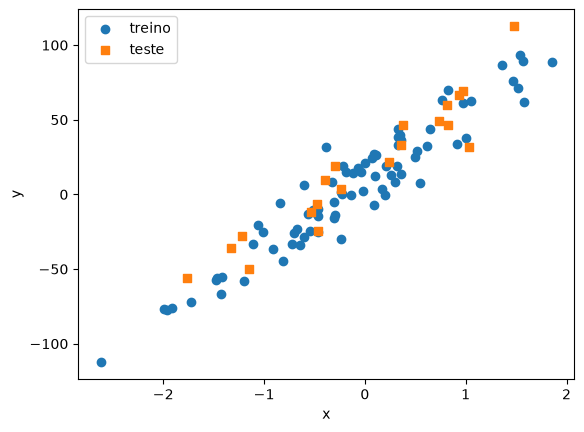

In [3]:
plt.scatter(x_train, y_train, label="treino")
plt.scatter(x_test, y_test, marker="s", label="teste")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## Treinamento com os hiperparâmetros padrão

Agora, vamos testar os modelos criados por mim. É esperado que ambos reproduzam resultados semelhantes.

Vale ressaltar que o método com gradientes usa, por padrão, 100 iterações e uma taxa de aprendizado de 0,01. Isso significa que ele percorre um *loop* cem vezes e, em cada uma delas, subtrai dos parâmetros os respectivos gradientes multiplicados pela taxa de aprendizado. Essa taxa controla o tamanho do passo: se for pequena demais, a convergência é lenta; se for grande demais, os parâmetros podem "pular" o mínimo. Também precisamos conferir se esses valores padrão são suficientes.

In [4]:
model_analitico.fit(x_train, y_train)
model_gd.fit(x_train, y_train)

for nome, m in [("sem Gradientes", model_analitico), ("com Gradientes", model_gd)]:
    print(f"Regressão Linear ({nome}): R² = {m.r2(x_test, y_test):.6f} | MSE = {mse(m, x_test, y_test):.4f}")

Regressão Linear (sem Gradientes): R² = 0.874200 | MSE = 234.4550
Regressão Linear (com Gradientes): R² = 0.801317 | MSE = 370.2868


Um *score* alto e um *MSE* baixo caracterizam um bom modelo; seus inversos denunciam um modelo ruim. Ambas as métricas acima foram calculadas no **conjunto de teste**.

O método sem gradientes atingiu um *score* mais alto que o segundo. Não é grande surpresa: ele encontra diretamente o ponto mínimo global, enquanto o método com gradientes precisa procurá-lo passo a passo. É provável que mais iterações, ou outra taxa de aprendizado, o aproximem do resultado analítico. Primeiro, vamos conferir a curva de perda (*loss*) do treino:

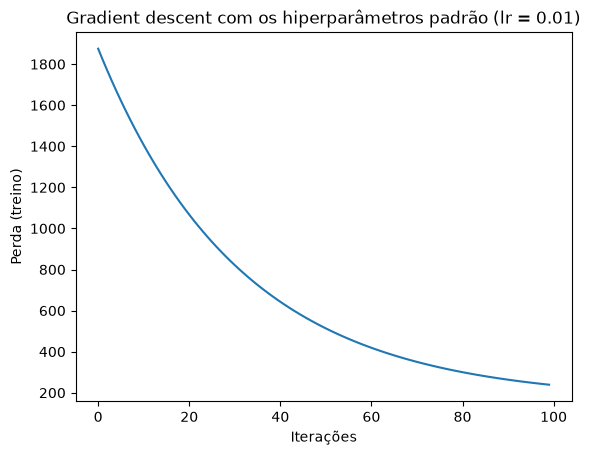

In [5]:
plt.plot(model_gd.loss_history)
plt.xlabel("Iterações")
plt.ylabel("Perda (treino)")
plt.title("Gradient descent com os hiperparâmetros padrão (lr = 0.01)")
plt.show()

## Quantas iterações são necessárias?

A curva de perda, sozinha, não diz se o treino terminou de convergir. Um critério melhor é comparar com a solução analítica, que é o ponto exato que o gradiente deveria alcançar. Os parâmetros que escolhemos nós, e não o algoritmo (como o número de iterações e a taxa de aprendizado), são chamados de *hiperparâmetros*.

Como testar diferentes valores à mão seria exaustivo, montaremos uma função simples: ela treina o modelo com um número crescente de iterações e devolve o menor número para o qual os pesos do gradiente ficam a menos de `tol` dos pesos da solução analítica.

Usamos os pesos analíticos como referência, e não o R² de teste, por dois motivos: o R² de teste tem um teto imposto pelo ruído dos dados (a solução analítica já é o melhor que uma reta pode fazer no treino) e escolher hiperparâmetros olhando o conjunto de teste contaminaria a avaliação final.

In [6]:
def iteracoes_ate_convergir(lr, tol=1e-3, passo=10, max_epochs=3000):
    for n_epochs in range(passo, max_epochs + 1, passo):
        m = RegressaoLinearGD()
        m.fit(x_train, y_train, epochs=n_epochs, learning_rate=lr)
        if abs(m.weight - model_analitico.weight) < tol and abs(m.bias - model_analitico.bias) < tol:
            return n_epochs
    return None   # não convergiu dentro de max_epochs

In [7]:
for lr in [0.001, 0.01, 0.05, 0.1]:
    n_iter = iteracoes_ate_convergir(lr)
    resultado = f"{n_iter} iterações" if n_iter else "não convergiu em 3000 iterações"
    print(f"Learning rate {lr:<6} -> {resultado}")

Learning rate 0.001  -> não convergiu em 3000 iterações
Learning rate 0.01   -> 690 iterações
Learning rate 0.05   -> 140 iterações
Learning rate 0.1    -> 70 iterações


Quanto maior a taxa de aprendizado, menos iterações são necessárias (até um limite, como veremos adiante). Com o valor padrão (0,01), o gradiente precisa de algumas centenas de iterações, mais do que as 100 usadas por padrão, o que explica o resultado inferior de antes. Já com `lr = 0.1`, bastam dezenas, e as 100 iterações padrão são suficientes. Vamos testar:

In [8]:
model_gd_v2 = RegressaoLinearGD()
model_gd_v2.fit(x_train, y_train, epochs=100, learning_rate=0.1)

print(f"R² (teste): {model_gd_v2.r2(x_test, y_test):.6f}")
print(f"MSE (teste): {mse(model_gd_v2, x_test, y_test):.4f}")

R² (teste): 0.874200
MSE (teste): 234.4550


Com apenas uma mudança na taxa de aprendizado, o gradiente atinge os mesmos R² e MSE da solução analítica. Vamos comparar as curvas de perda dos dois modelos:

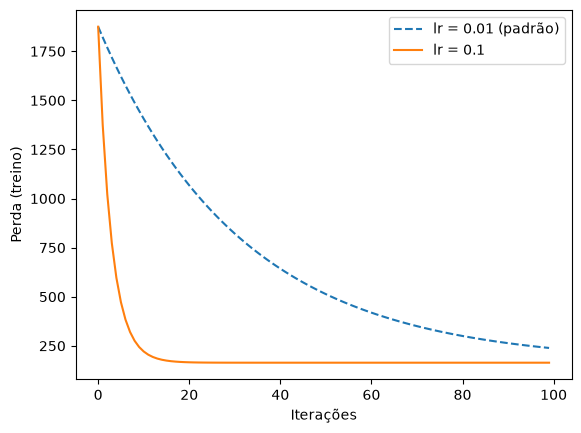

In [9]:
plt.plot(model_gd.loss_history, linestyle="--", label="lr = 0.01 (padrão)")
plt.plot(model_gd_v2.loss_history, label="lr = 0.1")
plt.xlabel("Iterações")
plt.ylabel("Perda (treino)")
plt.legend()
plt.show()

Note como a curva com `lr = 0.1` chega ao fundo muito mais rápido: a taxa de aprendizado maior aumenta o tamanho dos passos dados pelos gradientes.

Um *score* de aproximadamente 0,87 é o melhor que conseguimos nesse conjunto de teste, mas isso não é uma limitação do gradiente: ele convergiu para a mesma solução da fórmula analítica, que já é a melhor reta possível para os dados de treino. A distância até 1 vem do ruído do próprio *dataset* (`noise=15`), que nenhuma reta consegue explicar.

## Comparação com o scikit-learn

Agora, vejamos o que o modelo do *scikit-learn* tem a nos dizer. Para usá-lo, precisamos dar à variável independente o formato esperado, uma matriz com uma coluna.

In [10]:
X_train = x_train.reshape(-1, 1)
X_test = x_test.reshape(-1, 1)

model_sklearn.fit(X_train, y_train)

print(f"R² (teste): {model_sklearn.score(X_test, y_test):.6f}")
print(f"MSE (teste): {mse(model_sklearn, X_test, y_test):.4f}")

R² (teste): 0.874200
MSE (teste): 234.4550


Os resultados coincidem com os da solução analítica e do gradiente com `lr = 0.1`. Vamos comparar os pesos:

In [11]:
pesos = {
    "Analítico":        (model_analitico.weight, model_analitico.bias),
    "Gradient descent": (model_gd_v2.weight, model_gd_v2.bias),
    "scikit-learn":     (model_sklearn.coef_[0], model_sklearn.intercept_),
}

for nome, (w, b) in pesos.items():
    print(f"{nome:<18} w = {w:.8f}   b = {b:.8f}")

print()
for a, b in [("Gradient descent", "Analítico"), ("Gradient descent", "scikit-learn"), ("Analítico", "scikit-learn")]:
    print(f"{a} bate com {b}? {np.allclose(pesos[a], pesos[b], atol=1e-4)}")

Analítico          w = 45.49572308   b = 10.14883332
Gradient descent   w = 45.49572061   b = 10.14883198
scikit-learn       w = 45.49572308   b = 10.14883332

Gradient descent bate com Analítico? True
Gradient descent bate com scikit-learn? True
Analítico bate com scikit-learn? True


Os valores diferem apenas nas últimas casas decimais (a diferença é ínfima, da ordem de $10^{-6}$ no caso do gradiente, que para de iterar um pouco antes do ponto exato). Na prática, são os mesmos pesos, e por isso a comparação foi unânime: técnicas diferentes convergiram para o mesmo resultado, afinal, partiram da mesma função de perda.

Agora, o gráfico mais básico desse tipo de análise. As três retas se sobrepõem, então foram desenhadas com espessuras e estilos diferentes para que todas fiquem visíveis:

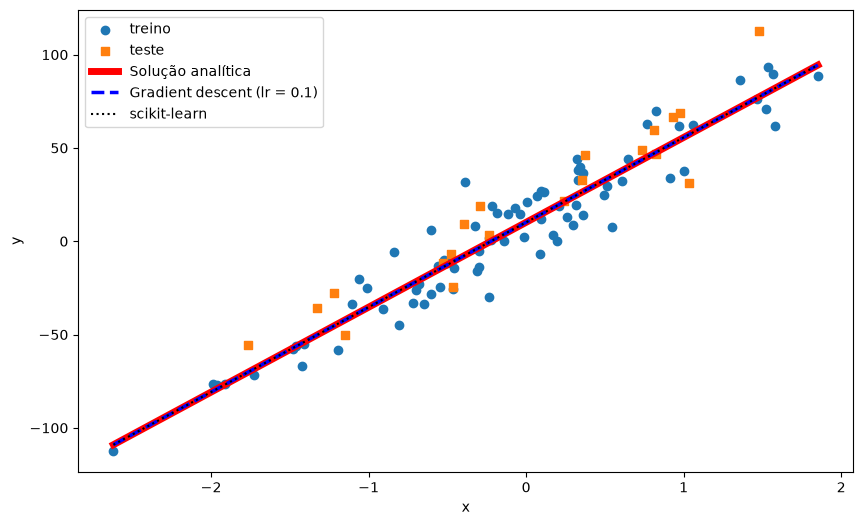

In [12]:
xs = np.linspace(x.min(), x.max(), 200)

plt.figure(figsize=(10, 6))
plt.scatter(x_train, y_train, label="treino")
plt.scatter(x_test, y_test, marker="s", label="teste")
plt.plot(xs, model_analitico.predict(xs), color="red", linewidth=5, label="Solução analítica")
plt.plot(xs, model_gd_v2.predict(xs), color="blue", linewidth=2.5, linestyle="--", label="Gradient descent (lr = 0.1)")
plt.plot(xs, model_sklearn.predict(xs.reshape(-1, 1)), color="black", linewidth=1.5, linestyle=":", label="scikit-learn")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

As três retas são, a olho nu, idênticas. Isso indica que as implementações foram desenvolvidas com sucesso.

## O que acontece quando a taxa de aprendizado é grande demais?

Vimos que aumentar `lr` acelera a convergência. Mas há um limite. Perto do mínimo, a perda é aproximadamente uma parábola, e a sua curvatura é dada pelos autovalores $\lambda$ da Hessiana da MSE em relação a $(w, b)$. Nessa região, cada passo do gradiente multiplica a distância até o mínimo por $(1 - lr \cdot \lambda)$. Portanto:

- se $|1 - lr \cdot \lambda| < 1$ para todos os $\lambda$, o erro encolhe a cada iteração (e quanto mais perto de 0, mais rápido);
- se algum $|1 - lr \cdot \lambda| > 1$, o erro cresce e o gradiente **diverge**. O limite é $lr < 2/\lambda_{max}$.

Vamos calcular esse limite para os nossos dados e comparar curvas de perda com taxas abaixo e acima dele:

Autovalores da Hessiana: [1.528 2.14 ]
Taxa de aprendizado crítica (2 / λ_max): 0.934


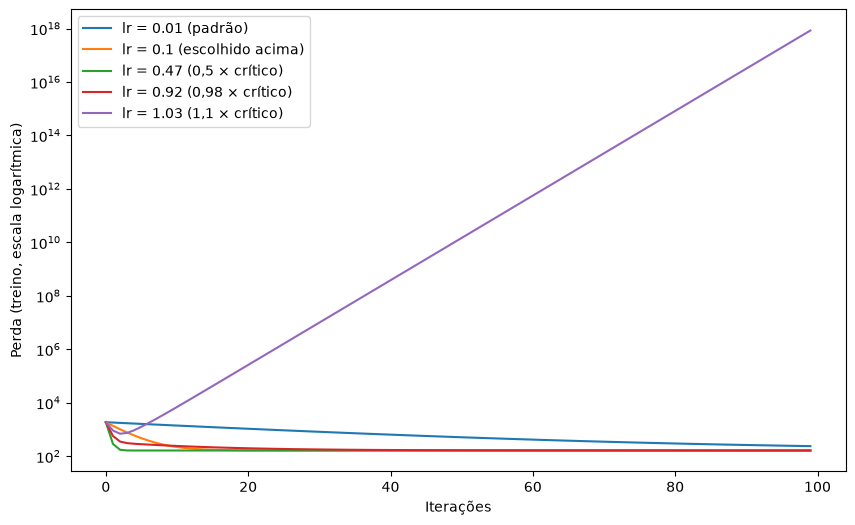

In [13]:
# Hessiana da MSE em relação a (w, b), calculada com os dados de treino
H = 2 * np.array([[np.mean(x_train ** 2), np.mean(x_train)],
                  [np.mean(x_train),      1.0]])
autovalores = np.linalg.eigvalsh(H)
lr_critico = 2 / autovalores.max()
print(f"Autovalores da Hessiana: {np.round(autovalores, 3)}")
print(f"Taxa de aprendizado crítica (2 / λ_max): {lr_critico:.3f}")

taxas = {
    "0.01 (padrão)": 0.01,
    "0.1 (escolhido acima)": 0.1,
    f"{0.5 * lr_critico:.2f} (0,5 × crítico)": 0.5 * lr_critico,
    f"{0.98 * lr_critico:.2f} (0,98 × crítico)": 0.98 * lr_critico,
    f"{1.1 * lr_critico:.2f} (1,1 × crítico)": 1.1 * lr_critico,
}

plt.figure(figsize=(10, 6))
for nome, lr in taxas.items():
    m = RegressaoLinearGD()
    m.fit(x_train, y_train, epochs=100, learning_rate=lr)
    plt.plot(m.loss_history, label=f"lr = {nome}")
plt.yscale("log")
plt.xlabel("Iterações")
plt.ylabel("Perda (treino, escala logarítmica)")
plt.legend()
plt.show()

A velocidade não cresce indefinidamente com a taxa de aprendizado. Com `lr` em torno de metade do valor crítico, a perda cai quase de imediato. Com 0,98 do valor crítico, o fator $(1 - lr \cdot \lambda)$ se aproxima de $-1$ ao longo da direção de maior curvatura: os parâmetros passam a oscilar em torno do mínimo e a convergência fica visivelmente mais lenta que a de metade do crítico. Acima do limite (1,1 do valor crítico), a perda cresce a cada iteração: o gradiente **diverge**.

A escala dos dados também importa, porque ela altera os autovalores. Multiplicando $x$ por 10, por exemplo:

In [14]:
for fator in [1, 10]:
    xs_escala = fator * x_train
    Hs = 2 * np.array([[np.mean(xs_escala ** 2), np.mean(xs_escala)],
                       [np.mean(xs_escala),      1.0]])
    lam = np.linalg.eigvalsh(Hs)
    print(f"x × {fator:<2} -> autovalores = {np.round(lam, 2)} | lr crítico = {2 / lam.max():.4f} | número de condição = {lam.max() / lam.min():.1f}")

x × 1  -> autovalores = [1.53 2.14] | lr crítico = 0.9344 | número de condição = 1.4
x × 10 -> autovalores = [  1.96 166.91] | lr crítico = 0.0120 | número de condição = 85.2


Com a escala maior, o limite de estabilidade despenca. Pior: o parâmetro $b$ (com $\lambda$ pequeno) continua precisando de muitas iterações, enquanto $w$ (com $\lambda$ enorme) exige um `lr` minúsculo. Essa razão entre o maior e o menor autovalor é o *número de condição*, e é a razão pela qual se padronizam as variáveis (média 0, desvio 1) antes de usar gradiente: assim todos os $\lambda$ ficam próximos, e uma única taxa de aprendizado serve para todos os parâmetros.

## Limitações

- **Uma única variável:** as implementações tratam apenas uma característica. O passo natural seguinte é generalizá-las para várias variáveis, em forma matricial ($w = (X^TX)^{-1}X^Ty$ para a solução analítica, e o gradiente vetorizado).
- **Solução analítica:** exige que $X^TX$ seja invertível (variáveis colineares a quebram) e fica cara quando há muitas variáveis. Na prática, usa-se `np.linalg.lstsq`, que resolve o problema via SVD em vez de inverter a matriz.
- **Gradiente:** depende da escolha de `lr` e do número de iterações, e é sensível à escala das variáveis, como vimos.
- **Dados sintéticos:** o *dataset* foi gerado a partir de uma reta mais ruído gaussiano, o cenário ideal para a regressão linear. Dados reais podem violar essas hipóteses.

## Conclusão

- A solução analítica, o gradiente descendente (com `lr` adequado) e o `scikit-learn` chegaram aos mesmos pesos, com diferença da ordem de $10^{-6}$.
- Com os hiperparâmetros padrão, o gradiente ficou para trás por **não ter convergido**, e não por ser um método pior. Aumentar a taxa de aprendizado de 0,01 para 0,1 resolveu, sem precisar de mais iterações.
- O R² de aproximadamente 0,87 é limitado pelo ruído dos dados, e não pelo otimizador.
- Há um limite superior para a taxa de aprendizado ($2/\lambda_{max}$), que depende da curvatura da perda e, portanto, da escala das variáveis.